# Decision Models for Alert Routing: Urgent, Routine or Noise
This notebook simulates a shared queue of a few thousand alerts and tickets, gives each one a fake "decision model" probability for urgent, routine and noise, and routes them with confidence thresholds. It measures how much work goes to a human, how many urgent cases slip through, and how many false alarms reach the pager.

**All data here is simulated.** No real alerts, no real model, and no API calls. The labels and probabilities are generated in code with a fixed random seed, so you get the same numbers I do.

## Step 1: Set up
Only numpy, pandas and matplotlib. The seed is fixed at 42, so every run gives the same queue.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
LABELS = ["urgent", "routine", "noise"]
N = 3000

## Step 2: Simulate the queue and the model's answers
This is the part a real shadow-mode export would replace. Each item gets a true label, which stands for what the on-call human actually did with it. Most items are noise, a good share are routine, and only a few are urgent, which is roughly what I see in small ops teams.

Then I fake a decision model. Every item gets a random score for each option, and the true option gets a boost. Some items are easy and get a big boost. Others are hard and get a small one. Tickets are a bit harder than alerts, because people write them by hand. About one item in ten is ambiguous and also boosts a wrong option. I also made the model a bit **overconfident** on purpose, because that is the failure I expect on house data, and the calibration chart should catch it.

In [2]:
true = rng.choice(3, size=N, p=[0.08, 0.37, 0.55])
source = rng.choice(["alert", "ticket"], size=N, p=[0.7, 0.3])

# How clearly each item points at its true bucket (higher = easier)
signal = rng.normal(2.2, 1.0, N) - 0.4 * (source == "ticket")
signal = np.clip(signal, 0.0, None)

logits = rng.normal(0.0, 1.0, size=(N, 3))
logits[np.arange(N), true] += signal

# Ambiguous items: a wrong option also looks plausible
ambiguous = rng.random(N) < 0.10
wrong = (true + rng.integers(1, 3, N)) % 3
logits[np.arange(N)[ambiguous], wrong[ambiguous]] += rng.normal(1.8, 0.5, ambiguous.sum())

# Softmax with a sharpening factor > 1, which makes the model overconfident
sharpen = 1.5
z = sharpen * logits
z -= z.max(axis=1, keepdims=True)
probs = np.exp(z) / np.exp(z).sum(axis=1, keepdims=True)

pred = probs.argmax(axis=1)
conf = probs.max(axis=1)
correct = pred == true

df = pd.DataFrame({
    "source": source,
    "true": [LABELS[i] for i in true],
    "p_urgent": probs[:, 0].round(3),
    "p_routine": probs[:, 1].round(3),
    "p_noise": probs[:, 2].round(3),
    "predicted": [LABELS[i] for i in pred],
    "confidence": conf.round(3),
})

print(f"Items in queue: {N}")
print(df["true"].value_counts().reindex(LABELS).to_string())
print(f"\nTop-choice accuracy with no threshold at all: {correct.mean():.1%}")
print(f"Accuracy on alerts: {correct[source == 'alert'].mean():.1%}, "
      f"on tickets: {correct[source == 'ticket'].mean():.1%}")
df.head(8)

Items in queue: 3000
true
urgent      227
routine    1128
noise      1645

Top-choice accuracy with no threshold at all: 79.8%
Accuracy on alerts: 82.7%, on tickets: 72.5%


,source,true,p_urgent,p_routine,p_noise,predicted,confidence
0,ticket,noise,0.008,0.003,0.989,noise,0.989
1,alert,routine,0.002,0.990,0.008,routine,0.990
2,alert,noise,0.005,0.005,0.990,noise,0.990
3,ticket,noise,0.722,0.048,0.230,urgent,0.722
4,alert,routine,0.138,0.618,0.245,routine,0.618
5,ticket,noise,0.043,0.014,0.943,noise,0.943
6,alert,noise,0.036,0.068,0.896,noise,0.896
7,alert,noise,0.001,0.000,0.998,noise,0.998


## Step 3: Coverage versus accuracy
Here is the first plot from the post. For each threshold between 0.5 and 0.99, I count how many items the model is allowed to route by itself (coverage) and how often those automatic decisions are right (accuracy). Everything below the line goes to the human queue.

Raising the threshold buys accuracy and costs coverage. What you are looking for is the spot where the human queue is small enough to read and the automatic decisions are good enough to trust.

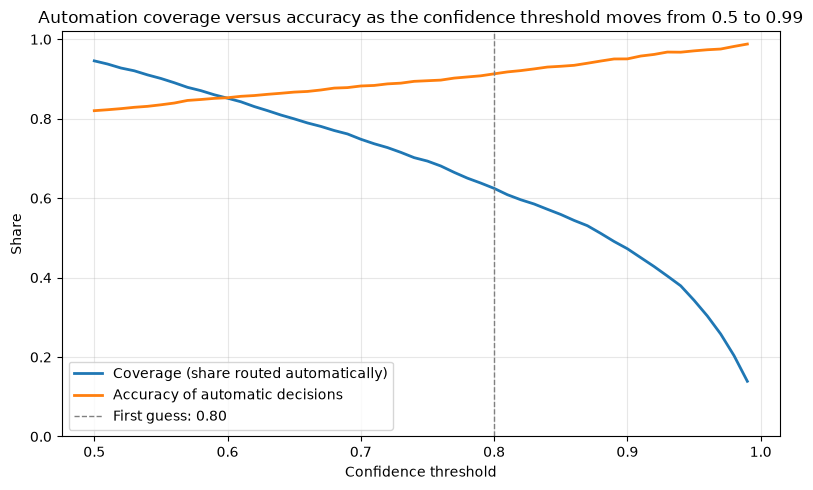

threshold 0.50: auto-routed  94.6%, accuracy  82.0%, to human   5.4%
threshold 0.70: auto-routed  74.8%, accuracy  88.2%, to human  25.2%
threshold 0.80: auto-routed  62.5%, accuracy  91.3%, to human  37.5%
threshold 0.90: auto-routed  47.3%, accuracy  95.1%, to human  52.7%
threshold 0.95: auto-routed  34.3%, accuracy  97.1%, to human  65.7%


In [3]:
thresholds = np.linspace(0.5, 0.99, 50)
coverage = np.array([(conf >= t).mean() for t in thresholds])
accuracy = np.array([correct[conf >= t].mean() if (conf >= t).any() else np.nan
                     for t in thresholds])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thresholds, coverage, label="Coverage (share routed automatically)", linewidth=2)
ax.plot(thresholds, accuracy, label="Accuracy of automatic decisions", linewidth=2)
ax.axvline(0.80, color="grey", linestyle="--", linewidth=1, label="First guess: 0.80")
ax.set_xlabel("Confidence threshold")
ax.set_ylabel("Share")
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.3)
ax.legend(loc="lower left")
plt.title("Automation coverage versus accuracy as the confidence threshold moves from 0.5 to 0.99")
plt.tight_layout()
plt.show()

for t in [0.5, 0.7, 0.8, 0.9, 0.95]:
    m = conf >= t
    print(f"threshold {t:.2f}: auto-routed {m.mean():6.1%}, accuracy {correct[m].mean():6.1%}, "
          f"to human {1 - m.mean():6.1%}")

## Step 4: Is "0.9 confident" really right nine times out of ten?
This is the calibration check. I group the predictions into confidence buckets and compare the average confidence in each bucket with how often the model was actually right. A perfectly calibrated model sits on the diagonal. Bars below the diagonal mean overconfidence: the model says 0.9 and delivers less.

With three options the top probability can never drop below one third, so the buckets start there.

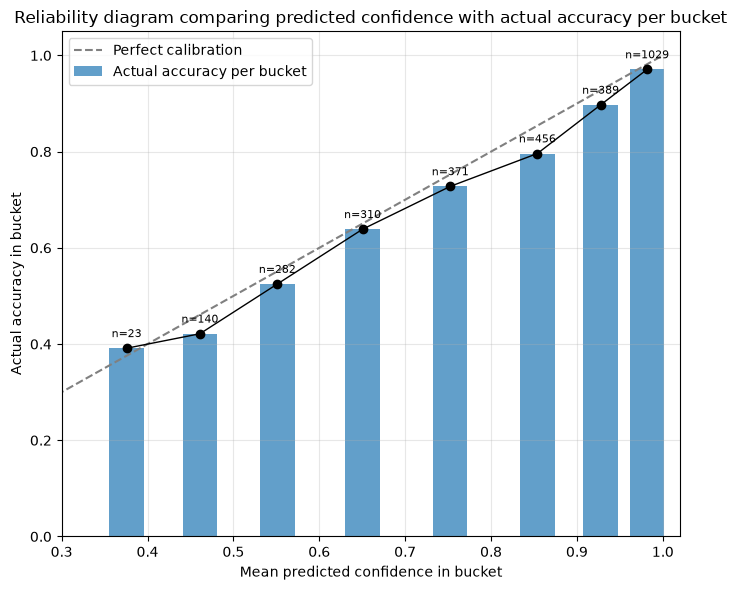

   bucket    n  mean_confidence  actual_accuracy    gap
0.33-0.40   23            0.376            0.391 -0.016
0.40-0.50  140            0.461            0.421  0.040
0.50-0.60  282            0.551            0.525  0.026
0.60-0.70  310            0.650            0.639  0.012
0.70-0.80  371            0.753            0.728  0.025
0.80-0.90  456            0.854            0.796  0.058
0.90-0.95  389            0.928            0.897  0.030
0.95-1.00 1029            0.982            0.971  0.011

Expected calibration error: 0.025
Average gap (confidence minus accuracy): +0.025  (positive = overconfident)


In [4]:
edges = np.array([1/3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0001])
bucket = np.digitize(conf, edges) - 1

rows = []
for b in range(len(edges) - 1):
    m = bucket == b
    if m.sum() == 0:
        continue
    rows.append({
        "bucket": f"{edges[b]:.2f}-{min(edges[b+1], 1.0):.2f}",
        "n": int(m.sum()),
        "mean_confidence": conf[m].mean(),
        "actual_accuracy": correct[m].mean(),
    })
calib = pd.DataFrame(rows)
calib["gap"] = calib["mean_confidence"] - calib["actual_accuracy"]
ece = (calib["n"] * calib["gap"].abs()).sum() / N

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Perfect calibration")
ax.bar(calib["mean_confidence"], calib["actual_accuracy"], width=0.04,
       alpha=0.7, label="Actual accuracy per bucket")
ax.plot(calib["mean_confidence"], calib["actual_accuracy"], marker="o", color="black", linewidth=1)
for _, r in calib.iterrows():
    ax.annotate(f"n={r['n']}", (r["mean_confidence"], r["actual_accuracy"]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set_xlim(0.3, 1.02)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Mean predicted confidence in bucket")
ax.set_ylabel("Actual accuracy in bucket")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")
plt.title("Reliability diagram comparing predicted confidence with actual accuracy per bucket")
plt.tight_layout()
plt.show()

print(calib.round(3).to_string(index=False))
print(f"\nExpected calibration error: {ece:.3f}")
print(f"Average gap (confidence minus accuracy): {(conf - correct).mean():+.3f}  "
      "(positive = overconfident)")

## Step 5: One line per destination, not one line for everything
This answers the question from the post. A single 0.80 line treats every mistake as equal, and they are not. So I set one threshold per destination, based on what a mistake there costs:

* **Noise** needs very high confidence (0.95). A wrong "noise" means silence during an outage.
* **Urgent** can use a lower bar (0.70). A false page is bad but survivable.
* **Routine** sits in the middle (0.85).

Anything that does not clear the bar for its top option goes to the human review queue. Then I count the three numbers I care about: how much lands on a human, how many urgent items get routed somewhere other than the pager, and how many non-urgent items wake someone up.

In [5]:
def route(probs, thr_by_class):
    p = probs.argmax(axis=1)
    c = probs.max(axis=1)
    auto = c >= np.asarray(thr_by_class)[p]
    return np.where(auto, p, 3)  # 3 = human review

def summarise(routed, name):
    auto = routed != 3
    return {
        "policy": name,
        "to_human": (~auto).mean(),
        "auto_accuracy": (routed[auto] == true[auto]).mean(),
        "missed_urgent": int(((true == 0) & np.isin(routed, [1, 2])).sum()),
        "urgent_to_noise": int(((true == 0) & (routed == 2)).sum()),
        "false_pages": int(((routed == 0) & (true != 0)).sum()),
        "noise_paged": int(((routed == 0) & (true == 2)).sum()),
    }

policies = {
    "no threshold": [0.0, 0.0, 0.0],
    "single 0.80": [0.80, 0.80, 0.80],
    "per destination (0.70 / 0.85 / 0.95)": [0.70, 0.85, 0.95],
}
results = pd.DataFrame([summarise(route(probs, t), name) for name, t in policies.items()])

chosen = policies["per destination (0.70 / 0.85 / 0.95)"]
routed = route(probs, chosen)

print(f"Urgent items in the queue: {(true == 0).sum()}")
print(results.to_string(index=False, formatters={
    "to_human": "{:.1%}".format, "auto_accuracy": "{:.1%}".format}))

Urgent items in the queue: 227
                              policy to_human auto_accuracy  missed_urgent  urgent_to_noise  false_pages  noise_paged
                        no threshold     0.0%         79.8%             53               21          267          162
                         single 0.80    37.5%         91.3%             14                4           69           43
per destination (0.70 / 0.85 / 0.95)    52.1%         88.7%              8                0          112           75


## Step 6: The confusion matrix, read by cost
Rows are what the human actually did. Columns are where the router sent the item, and the human review queue gets its own column. The cells to read first are **urgent → noise** (an outage nobody hears about) and **noise → urgent** (a page for nothing). Urgent and routine items that land in the human column are fine. That is the system being honest about what it does not know.

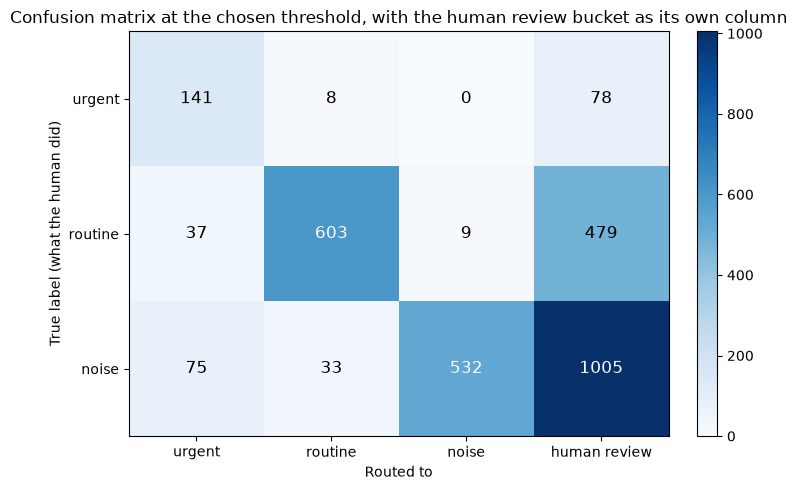

              urgent  routine  noise  human review
true urgent      141        8      0            78
true routine      37      603      9           479
true noise        75       33    532          1005

Sent to a human:            52.1% of 3000 items
Automatic decisions right:  88.7%
Urgent missed (auto-routed elsewhere): 8 of 227, of which sent to noise: 0
False alarms on the pager:  112 (pure noise paged: 75)


In [6]:
cols = ["urgent", "routine", "noise", "human review"]
cm = np.zeros((3, 4), dtype=int)
np.add.at(cm, (true, routed), 1)

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(cm, cmap="Blues")
for i in range(3):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
ax.set_xticks(range(4))
ax.set_xticklabels(cols)
ax.set_yticks(range(3))
ax.set_yticklabels(LABELS)
ax.set_xlabel("Routed to")
ax.set_ylabel("True label (what the human did)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.title("Confusion matrix at the chosen threshold, with the human review bucket as its own column")
plt.tight_layout()
plt.show()

print(pd.DataFrame(cm, index=[f"true {l}" for l in LABELS], columns=cols).to_string())
r = summarise(routed, "chosen")
print(f"\nSent to a human:            {r['to_human']:.1%} of {N} items")
print(f"Automatic decisions right:  {r['auto_accuracy']:.1%}")
print(f"Urgent missed (auto-routed elsewhere): {r['missed_urgent']} of {(true == 0).sum()}, "
      f"of which sent to noise: {r['urgent_to_noise']}")
print(f"False alarms on the pager:  {r['false_pages']} (pure noise paged: {r['noise_paged']})")

## What I take from this
Compare the three policies in the Step 5 table. With no threshold, every mistake goes straight out. A single 0.80 line cuts mistakes but treats a missed outage like a swapped ticket. Per-destination thresholds push the dangerous mistakes, urgent sent to noise, toward zero, and they pay for it mostly with a bigger human queue. That is the trade I want.

The reliability diagram is the warning label. I built this fake model to be overconfident, and the chart shows it. On your own data you will not know in advance, so plot it before you trust any threshold.

To use this on real data, replace Step 2 with your shadow-mode export: one row per item, the human outcome, and the three probabilities. Everything after that stays the same.